# Real-to-Sim Sensor Model, Part 4: The Model (baseline, 7 inputs)
| Part | Notebook | What it does |
|---|---|---|
| 1–2 | `12_1`, `12_2` | Camera, CAD render (inputs), pose correction, labels |
| 3 | `12_3_real2sim_dataset` | 11.8 M rows: inputs + labels per pixel |
| **4** | **`12_4_real2sim_model`** | **Network: inputs → p, μ, σ for every pixel** |
| 5–6 | | Simulator, export |

**The model.** A small network looks at one pixel at a time:
```
inputs (from the CAD)            network            outputs (its prediction)
xn, yn, z, nx, ny, nz, θ   ─────►  [ MLP ]  ─────►   p  = chance the pixel is dropped
                                                     μ  = typical depth error (mm)
                                                     σ  = spread of the depth error (mm)
```
It is trained by comparing its outputs with the labels: **BCE** grades `p` against `y_drop` (every pixel), **Gaussian NLL** grades `μ, σ` against `e_z` (kept pixels only).

**This notebook is the baseline**: the 7 inputs of Part 1 only. The 3 context inputs of 12_3 are left for a separate step, so each change can be judged on its own.

**The split.** **TH1041AV is the test workpiece**: never used for training, scored once at the end. Of the other three (TH1021AV, TH1031AV, TH1051AV), a random 70% of each workpiece's views is used for training and 30% for validation (decides when to stop training). Note what the test measures: all four workpieces are the **same 60×80×40 mm block with a 15 mm deep pocket**; only the pocket length differs (50 / 40 / 30 / 20 mm). So this is a test on a new pocket length, not on a new shape.

In [1]:
# ==========================================
# CONFIGURATION
# ==========================================
import os
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import real2sim as rs
import real2sim_model as rm
from seed_utils import SEED, set_seed

EXPERIMENT = "test_11_real_pocket"
ALL_WORKPIECES = ["TH1021AV", "TH1031AV", "TH1041AV", "TH1051AV"]
TEST_WP = "TH1041AV"            # never used for training, scored once at the end
VAL_FRACTION = 0.3              # of every other workpiece, 30% of its views decide when training stops
INPUTS = rs.FEATURE_NAMES       # the 7 Part 1 inputs (baseline)
MAX_EPOCHS = 300                # upper limit; training normally stops earlier (PATIENCE)
PATIENCE = 15                   # stop after this many epochs without a better validation loss
LR = 1e-3                       # starting learning rate; halved after 5 epochs without improvement
EXAMPLE_VIEW = 100              # view of TEST_WP shown in section 4
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

cam = rs.Camera.native().downscaled(2)
OUT_DIR = f"simulation/real2sim/{EXPERIMENT}"
MODEL_PATH = os.path.join(OUT_DIR, f"model_{len(INPUTS)}in_test-{TEST_WP}.pt")
print(f"Inputs ({len(INPUTS)}): {INPUTS} | device {DEVICE}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Inputs (7): ['xn', 'yn', 'z', 'nx', 'ny', 'nz', 'theta_inc'] | device cuda


## 1. Data and split
- **train**: 70% of the views of TH1021AV, TH1031AV and TH1051AV (a whole view is either train or val)
- **val**: the other 30% of their views. Only used to decide when to stop and which epoch to keep.
- **test**: TH1041AV, all views. Used once at the end.

`rm.split_views` makes this split (seed 42), so every Part 4 and 5 notebook uses the same one.

In [2]:
# ==========================================
# 1. LOAD AND SPLIT
# ==========================================
df = rs.load_dataset(EXPERIMENT, ALL_WORKPIECES, cam)
split = rm.split_views(df, TEST_WP, VAL_FRACTION, seed=SEED)
is_train, is_val, is_test = split["train"], split["val"], split["test"]
display(pd.DataFrame({name: dict(workpieces=", ".join(sorted(df.workpiece[m].unique())), pixels=m.sum(),
                                 views=df[m].groupby(["workpiece", "view"], observed=True).ngroups,
                                 dropped=round(df.y_drop[m].mean(), 3)) for name, m in split.items()}).T)

,workpieces,pixels,views,dropped
train,"TH1021AV, TH1031AV, TH1051AV",6201468,606,0.237
val,"TH1021AV, TH1031AV, TH1051AV",2652191,258,0.231
test,TH1041AV,2916099,288,0.225


## 2. Train
One epoch = one pass over all ~6.2 million training pixels (~380 steps of 16,384 pixels). Training runs until the **validation loss stops improving**:
- after 5 epochs without improvement, the learning rate is halved (smaller, more careful steps);
- after `PATIENCE` (15) epochs without improvement, training stops, and the weights of the best epoch are restored and saved.

How to read the curves: train going down means the model fits the training views better; val going down means that carries over to other views. The dashed line marks the best epoch. Note that the val views show the **same parts** as the training views, so val cannot reveal whether the model is learning those parts instead of the sensor; only the unseen test workpiece can (section 3).

epoch   1  train BCE 0.4469 NLL 2.6729 | val BCE 0.3532 NLL 2.4957 | lr 1.0e-03 | best epoch 1
epoch   5  train BCE 0.2720 NLL 2.3723 | val BCE 0.2705 NLL 2.3874 | lr 1.0e-03 | best epoch 5
epoch  10  train BCE 0.2417 NLL 2.2589 | val BCE 0.2490 NLL 2.3106 | lr 1.0e-03 | best epoch 10
epoch  15  train BCE 0.2281 NLL 2.1973 | val BCE 0.2400 NLL 2.2918 | lr 1.0e-03 | best epoch 15
epoch  20  train BCE 0.2206 NLL 2.1599 | val BCE 0.2369 NLL 2.2966 | lr 1.0e-03 | best epoch 17
epoch  25  train BCE 0.2158 NLL 2.1343 | val BCE 0.2346 NLL 2.3013 | lr 1.0e-03 | best epoch 22
epoch  30  train BCE 0.2119 NLL 2.1121 | val BCE 0.2323 NLL 2.3190 | lr 5.0e-04 | best epoch 22
epoch  35  train BCE 0.2099 NLL 2.1000 | val BCE 0.2313 NLL 2.3243 | lr 2.5e-04 | best epoch 22
epoch  37  train BCE 0.2096 NLL 2.0980 | val BCE 0.2312 NLL 2.3295 | lr 2.5e-04 | best epoch 22
stopped: no improvement for 15 epochs; best epoch 22 restored
trained 37 epochs in 47 s, best epoch 22
saved simulation/real2sim/test_11_r

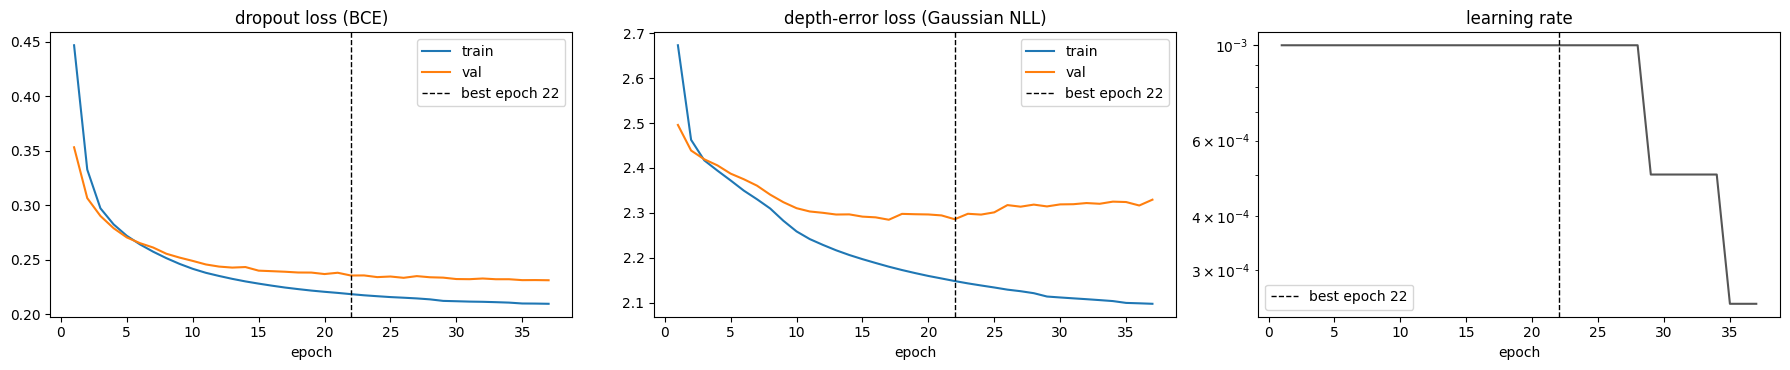

In [3]:
# ==========================================
# 2. TRAIN THE BASELINE
# ==========================================
def fit(inputs, log=print):
    data = {k: rm.to_tensors(df[m], inputs, DEVICE) for k, m in split.items()}
    set_seed(SEED)
    model = rm.SensorNet(len(inputs)).to(DEVICE)
    t0 = time.time()
    hist = pd.DataFrame(rm.train(model, data["train"], data["val"], max_epochs=MAX_EPOCHS, patience=PATIENCE,
                                 lr=LR, seed=SEED, log=log))
    best_epoch = int(hist.epoch[(hist.val_bce + hist.val_nll).idxmin()])
    if log:
        log(f"trained {len(hist)} epochs in {time.time() - t0:.0f} s, best epoch {best_epoch}")
    return model, hist, data


model, hist, data = fit(INPUTS)
best_epoch = int(hist.epoch[(hist.val_bce + hist.val_nll).idxmin()])
rm.save_model(MODEL_PATH, model, INPUTS, meta=dict(test_workpiece=TEST_WP, best_epoch=best_epoch,
                                                   epochs_run=len(hist), patience=PATIENCE, seed=SEED))
print(f"saved {MODEL_PATH}")

fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
for ax, key in zip(axes, ["bce", "nll"]):
    ax.plot(hist.epoch, hist[f"train_{key}"], "-", label="train")
    ax.plot(hist.epoch, hist[f"val_{key}"], "-", label="val")
    ax.set_title({"bce": "dropout loss (BCE)", "nll": "depth-error loss (Gaussian NLL)"}[key])
axes[2].semilogy(hist.epoch, hist.lr, "-", color="#555555")
axes[2].set_title("learning rate")
for ax in axes:
    ax.axvline(best_epoch, color="k", ls="--", lw=1, label=f"best epoch {best_epoch}")
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part4_training_7in.png"), dpi=110)
plt.show()

## 3. Is it good on the unseen workpiece?
Two questions, one figure each:
- **Left, dropout**: pixels are grouped by the `p` the model predicted. If the model is honest, the pixels where it said 30% should really be dropped about 30% of the time, so the dots lie on the diagonal.
- **Right, depth error**: for every kept pixel, (`e_z` − μ) / σ is how many σ's the real error is from the prediction. If μ and σ are right, this follows the standard bell curve (black): about **68%** within ±1 and **95%** within ±2.

The table compares the model with two simple references from 12_3 (trained on the same training workpieces): one average for every pixel, and the lookup table with angle + distance.

,dropout BCE (lower = better),e_z MAE (mm)
predictor,,
one average for every pixel,0.534,2.452
lookup table: angle + distance (12_3),0.532,2.455
"model, 7 inputs",0.280,2.241


model on TH1041AV: predicted dropout 23.4% vs real 22.5% | within 1 sigma 63.2% (ideal 68.3), within 2 sigma 90.5% (ideal 95.4) | median sigma 2.42 mm


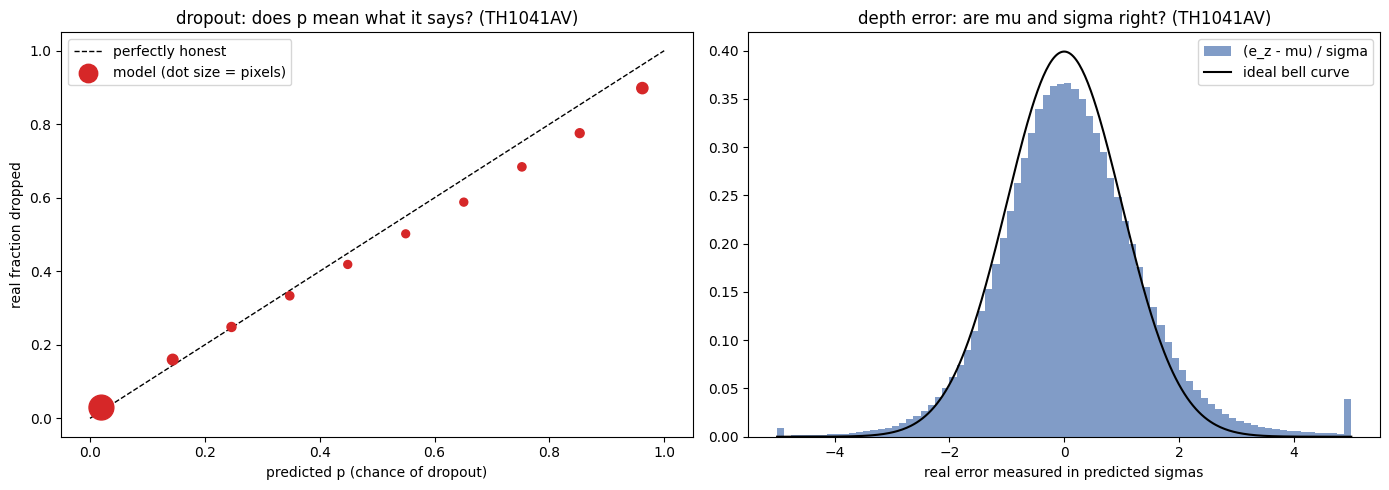

In [4]:
# ==========================================
# 3. SCORES AND CALIBRATION ON THE TEST WORKPIECE
# ==========================================
test = df[is_test].reset_index(drop=True)
p, mu, sd = rm.predict(model, data["test"][0])
y, e = test.y_drop.to_numpy(), test.e_z.to_numpy()
kept = ~np.isnan(e)


def bce(prob):
    prob = np.clip(prob, 1e-3, 1 - 1e-3)
    return float(-(y * np.log(prob) + (1 - y) * np.log(1 - prob)).mean())


train = df[is_train]
cuts = dict(angle=(lambda d: pd.cut(d.theta_inc, [0, 10, 20, 30, 40, 55, 70, 80, 90], include_lowest=True).cat.codes),
            distance=(lambda d: pd.cut(d.z, [0, 450, 500, 550, 2000]).cat.codes))
key_tr = pd.DataFrame({k: f(train) for k, f in cuts.items()})
key_te = pd.DataFrame({k: f(test) for k, f in cuts.items()})
lut = pd.concat([key_tr, train[["y_drop", "e_z"]].reset_index(drop=True)], axis=1).groupby(list(cuts))
lut_p = key_te.join(lut.y_drop.mean().rename("p"), on=list(cuts)).p.fillna(train.y_drop.mean()).to_numpy()
lut_mu = key_te.join(lut.e_z.median().rename("mu"), on=list(cuts)).mu.fillna(train.e_z.median()).to_numpy()

z = (e[kept] - mu[kept]) / sd[kept]
scores = pd.DataFrame([
    ("one average for every pixel", bce(np.full(len(y), train.y_drop.mean())), np.abs(e[kept] - train.e_z.median()).mean()),
    ("lookup table: angle + distance (12_3)", bce(lut_p), np.abs(e[kept] - lut_mu[kept]).mean()),
    (f"model, {len(INPUTS)} inputs", bce(p), np.abs(e[kept] - mu[kept]).mean()),
], columns=["predictor", "dropout BCE (lower = better)", "e_z MAE (mm)"]).set_index("predictor")
display(scores.round(3))
print(f"model on {TEST_WP}: predicted dropout {p.mean() * 100:.1f}% vs real {y.mean() * 100:.1f}% | "
      f"within 1 sigma {np.mean(np.abs(z) < 1) * 100:.1f}% (ideal 68.3), within 2 sigma {np.mean(np.abs(z) < 2) * 100:.1f}% (ideal 95.4) | "
      f"median sigma {np.median(sd[kept]):.2f} mm")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bins = np.linspace(0, 1, 11)
b = np.clip(np.digitize(p, bins) - 1, 0, 9)
cal = pd.DataFrame(dict(b=b, pred=p, real=y)).groupby("b").agg(n=("real", "size"), pred=("pred", "mean"), real=("real", "mean"))
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfectly honest")
axes[0].scatter(cal.pred, cal.real, s=20 + 300 * cal.n / cal.n.max(), color="#d62728", zorder=3, label="model (dot size = pixels)")
axes[0].set_xlabel("predicted p (chance of dropout)")
axes[0].set_ylabel("real fraction dropped")
axes[0].set_title(f"dropout: does p mean what it says? ({TEST_WP})")
axes[0].legend()
xs = np.linspace(-5, 5, 400)
axes[1].hist(np.clip(z, -5, 5), bins=np.linspace(-5, 5, 81), density=True, color="#4C72B0", alpha=0.7, label="(e_z - mu) / sigma")
axes[1].plot(xs, np.exp(-xs ** 2 / 2) / np.sqrt(2 * np.pi), "k", lw=1.5, label="ideal bell curve")
axes[1].set_xlabel("real error measured in predicted sigmas")
axes[1].set_title(f"depth error: are mu and sigma right? ({TEST_WP})")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part4_calibration_7in.png"), dpi=110)
plt.show()

## 4. What it predicts on one unseen view
Top row: what the real sensor did (labels). Bottom row: what the model predicts from the CAD alone. The model is not expected to reproduce the exact red pixels or blobs; those are random. It should get the **pattern**: where dropouts are likely (`p`), whether the depth reads too far or too close there (`μ`), and how noisy it is (`σ`).

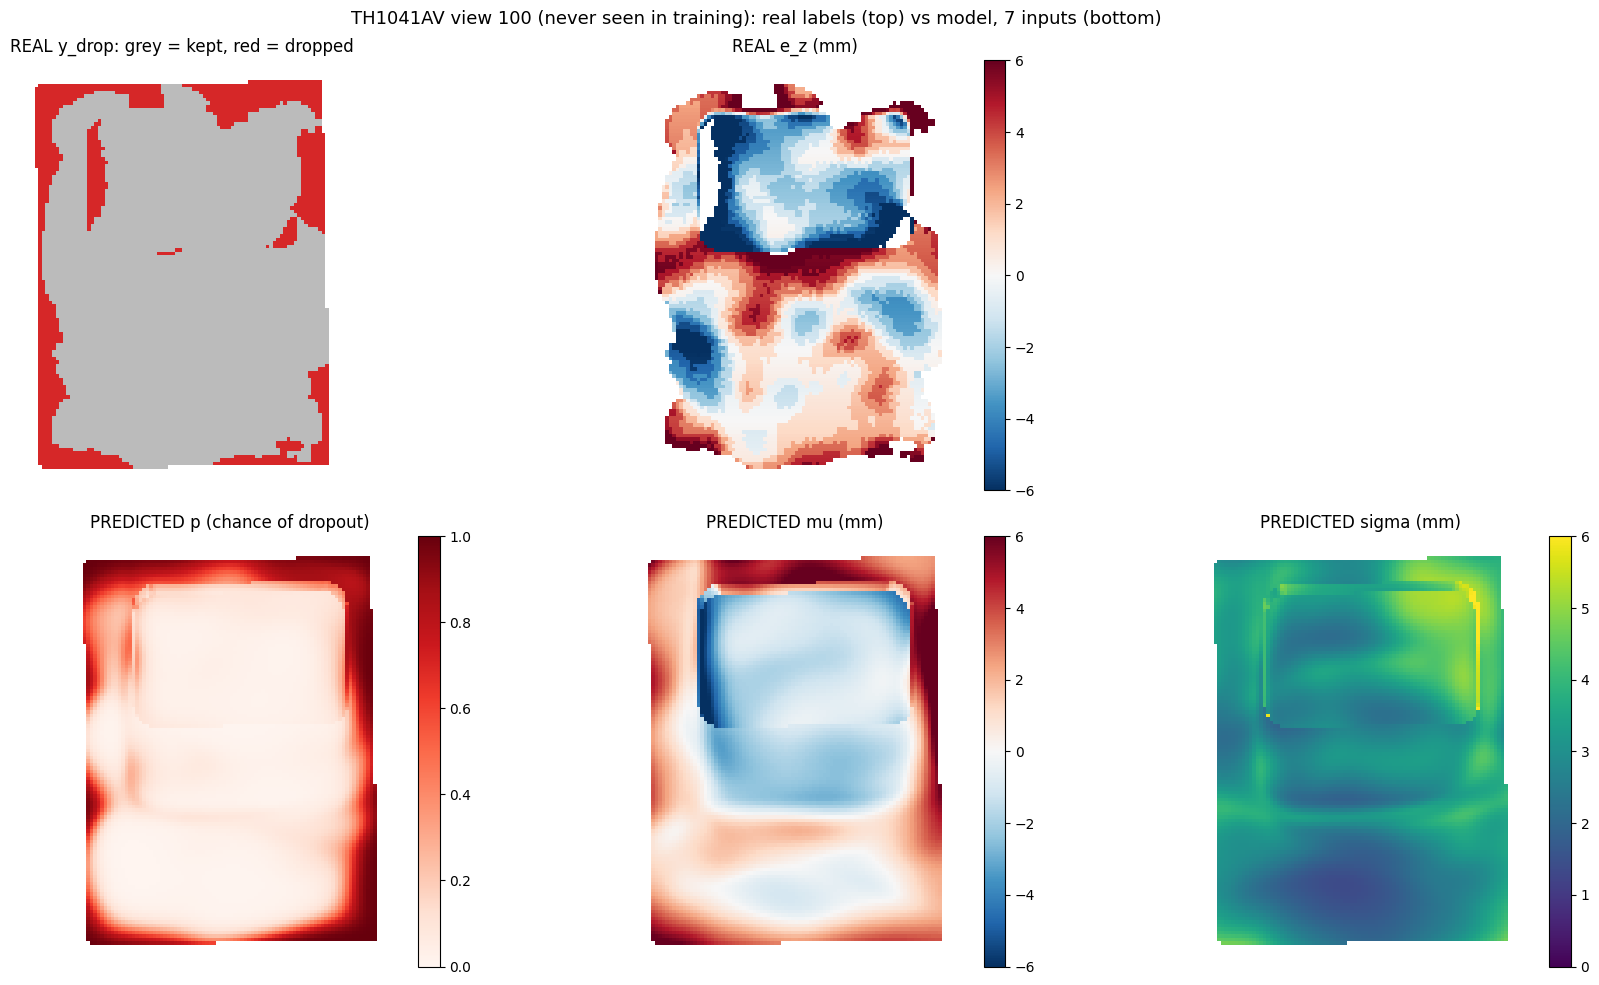

In [5]:
# ==========================================
# 4. MAPS FOR ONE TEST VIEW
# ==========================================
sel = (test.view == EXAMPLE_VIEW).to_numpy()
rows = test[sel]


def to_map(values):
    img = np.full((cam.height, cam.width), np.nan)
    img[rows.v.to_numpy(), rows.u.to_numpy()] = values
    return img


mask = ~np.isnan(to_map(np.ones(sel.sum())))
b0, b1, a0, a1 = rs.mask_bbox(mask, margin=6)
crop = (slice(b0, b1), slice(a0, a1))
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
panels = [  # (axis, image, colormap, vmin, vmax, title)
    (axes[0, 0], to_map(rows.y_drop), ListedColormap(["#bbbbbb", "#d62728"]), 0, 1, "REAL y_drop: grey = kept, red = dropped"),
    (axes[0, 1], to_map(rows.e_z), "RdBu_r", -6, 6, "REAL e_z (mm)"),
    (axes[1, 0], to_map(p[sel]), "Reds", 0, 1, "PREDICTED p (chance of dropout)"),
    (axes[1, 1], to_map(mu[sel]), "RdBu_r", -6, 6, "PREDICTED mu (mm)"),
    (axes[1, 2], to_map(sd[sel]), "viridis", 0, 6, "PREDICTED sigma (mm)"),
]
for ax, img, cmap, lo, hi, title in panels:
    im = ax.imshow(img[crop], cmap=cmap, vmin=lo, vmax=hi, interpolation="nearest")
    ax.set_title(title)
    if ax is not axes[0, 0]:
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle(f"{TEST_WP} view {EXAMPLE_VIEW} (never seen in training): real labels (top) vs model, {len(INPUTS)} inputs (bottom)", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part4_example_view_7in.png"), dpi=110)
plt.show()

## 5. What is the baseline relying on?
The same training, repeated **without `xn, yn`** (where the pixel is in the image). If the score barely changes, image position does not matter. If it gets much worse, the model is using image position for something.

Why it might: every workpiece is the same block, always near the image centre, and the views are at three fixed distances. So *where a pixel is in the image* together with its depth roughly tells the model *where on the block* the pixel is, including how close it is to the outer edges. That is a shortcut: it would not carry over to a differently shaped part, or to a view where the part is not centred.

In [6]:
# ==========================================
# 5. SAME MODEL WITHOUT xn, yn
# ==========================================
no_pos = [k for k in INPUTS if k not in ("xn", "yn")]
model_np, _, data_np = fit(no_pos, log=None)
p2, mu2, sd2 = rm.predict(model_np, data_np["test"][0])
z2 = (e[kept] - mu2[kept]) / sd2[kept]
cmp_ = pd.DataFrame([
    (f"{len(INPUTS)} inputs (baseline)", bce(p), np.abs(e[kept] - mu[kept]).mean(), np.mean(np.abs(z) < 1)),
    (f"{len(no_pos)} inputs: without xn, yn", bce(p2), np.abs(e[kept] - mu2[kept]).mean(), np.mean(np.abs(z2) < 1)),
], columns=["model", "dropout BCE", "e_z MAE (mm)", "within 1 sigma"]).set_index("model")
display(cmp_.round(3))

,dropout BCE,e_z MAE (mm),within 1 sigma
model,,,
7 inputs (baseline),0.280,2.241,0.632
"5 inputs: without xn, yn",0.373,2.157,0.709


## Summary of Part 4 step 1 (baseline, 7 inputs; train/val = 70/30 of the views of TH1021AV, TH1031AV, TH1051AV; test TH1041AV; seed 42)
### Must understand
- **Training** stops by patience. The best epoch is 22: after that the validation loss stops improving while the training loss keeps falling.
- **Scores on the unseen workpiece:**

  | Predictor | Dropout BCE | e_z error |
  |---|---|---|
  | one average for every pixel | 0.534 | 2.45 mm |
  | lookup table, angle + distance | 0.532 | 2.46 mm |
  | this model | **0.280** | **2.24 mm** |

- **The dropout rate is right, but σ is too narrow on the new part.** The model predicts 23.4% dropout against a real 22.5%. But only 63% of the real errors fall within ±1σ (ideal 68%) and 90.5% within ±2σ (ideal 95%): the model is more confident on a new part than it should be. This is a sign that part of what it learned is **the training parts** rather than the sensor. The validation views cannot catch this, because they show the same three parts as the training views.
- **A large part of the dropout score is a shortcut.** Without `xn, yn` the BCE goes from 0.280 to **0.373**. In section 4, the predicted `μ` contains a **ghost pocket much longer than TH1041AV's real 30 mm pocket**: an average of the training pockets (50, 40 and 20 mm), painted where pockets sit in the image. All workpieces are the same block, always centred, seen from three fixed distances, so image position plus depth tells the model *where on the average block* a pixel is.
- **Consequence:** the shortcut works for these 4 workpieces at these viewpoints. It would be wrong for a differently shaped part, a part that is not centred, or other distances.
- **What the baseline shows:** the training machinery works and `p` is calibrated. It also shows exactly what the 7 inputs are missing: where the edges are.

### Know what it does
- `rm.split_views`: the shared split, 70/30 of the views of each training workpiece, seed 42. A stricter split (validation on a whole separate workpiece) was compared for the final 10-input model and gave the same test scores, so the simpler split is used.
- `real2sim_model.py`:
  - `SensorNet`: an MLP with 3 × 128 hidden layers;
  - `losses`: BCE + Gaussian NLL;
  - `train`: Adam; it halves the learning rate after 5 epochs without improvement, stops after `PATIENCE` = 15 and restores the best epoch;
  - `predict`, `save_model`, `load_model`.
- Saved model: `simulation/real2sim/test_11_real_pocket/model_7in_test-TH1041AV.pt`. Training takes under a minute.

### Next (step 2, `12_4b`)
Add the 3 context inputs (`edge_mm`, `deeper_mm`, `closer_mm`), which tell the model directly where the edges are.